# Challenge Sprint 4: Investigação experimental de arquiteturas de CNN

**Integrantes:** Lucas Ferrari Lima (RM 563119) · Carlos Eduardo Pires Cervelli (RM 563462) · Felipe Krzyzanovski dos Santos Menezes (RM 564878) · Leonardo Lopes Oliveira (RM 565437) · Arthur de Souza Matos Dias (RM 566068) · Guilherme Carreri Giampietro (RM 565676) · Mateus Patrício Pereira (RM 564695)

**Objetivo:** descobrir, por experimentos controlados, **quantos blocos convolucionais** uma CNN precisa para classificar a espécie de planta nas imagens da DeepWeeds, usando exatamente os conjuntos Train / Validation / Test definidos na Sprint 3.

| # | Seção | Requisito da Sprint |
|---|---|---|
| 1 | Problema e modalidade | entrada e saída do modelo |
| 2 | Dataset e continuidade da Sprint 3 | mesma divisão, tamanho de entrada, pré-processamento |
| 3 | Arquitetura baseline | `model.summary()` e parâmetros |
| 4 | Experimentos de arquitetura | 2, 3, 4 e 5 blocos, uma mudança por vez |
| 5 | Comparação no Validation | tabela, gráfico e curvas (under/overfitting) |
| 6 | Arquitetura selecionada | escolha justificada pelo Validation |
| 7 | Avaliação final no Test | métricas, matriz de confusão, acertos e erros |
| 8 | Conclusão | impacto da profundidade, limitações, próximos passos |

> **Como executar no Google Colab**
> 1. *Ambiente de execução → Alterar o tipo de ambiente de execução → **GPU T4***.
> 2. Recomendado: rode primeiro com `QUICK_TEST = True` (poucas imagens, 2 épocas, ~3 min) para conferir que tudo funciona. Depois volte para `False`.
> 3. *Ambiente de execução → **Executar tudo***. Com `USE_DRIVE = True` o Colab pede acesso ao Google Drive: cada modelo treinado fica salvo em `MyDrive/sprint4_cnn/` e, se a sessão cair, basta executar tudo de novo que os modelos prontos são reaproveitados.
> 4. No final é gerado **`sprint4_resultados.zip`** (tabelas, curvas, figuras e métricas) e o download começa sozinho.

In [2]:
import json, os, shutil, sys, time, urllib.request, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from IPython.display import Markdown, display
from PIL import Image
from sklearn.metrics import f1_score

# ── Configuração ────────────────────────────────────────────────────────────
QUICK_TEST = False      # True = poucas imagens e 2 épocas, só para testar o notebook (~3 min)
USE_DRIVE = True        # True = salva resultados e images.zip no Google Drive (sobrevive a quedas do Colab)
SEED = 42
MARGIN = 0.01           # diferença de F1 macro tratada como empate na escolha (≈ ruído do Validation)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/sprint4_cnn")
else:
    BASE = Path("sprint4_cnn")
OUT = BASE / ("quick_test" if QUICK_TEST else "resultados")
RUNS, FIG = OUT / "runs", OUT / "figures"
RUNS.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path("data")         # imagens ficam no disco local da sessão (leitura rápida)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", gpus[0].name if gpus else "NENHUMA")
if gpus:
    keras.mixed_precision.set_global_policy("mixed_float16")   # T4: contas em float16, saída em float32
else:
    print("ATENÇÃO: sem GPU o treino leva horas. Ative a GPU em 'Ambiente de execução'.")
print("Resultados em:", OUT.resolve())

# ── Estilo dos gráficos ─────────────────────────────────────────────────────
C_TRAIN, C_VAL = "#2a78d6", "#eb6834"
C_BASE, C_SEL, C_OTHER = "#898781", "#4a3aa7", "#b9b3e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": False, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10,
})


def br(n):        # 5152 -> "5.152"
    return f"{int(round(n)):,}".replace(",", ".")


def pc(x, k=1):   # 0.3234 -> "32,3%"
    return f"{x * 100:.{k}f}%".replace(".", ",")


def pp(x, k=1):   # 0.0312 -> "+3,1 p.p."
    return f"{'+' if x >= 0 else '−'}{abs(x) * 100:.{k}f}".replace(".", ",") + " p.p."

Mounted at /content/drive
TensorFlow 2.21.0 | Keras 3.13.2 | GPU: /physical_device:GPU:0
Resultados em: /content/drive/MyDrive/sprint4_cnn/resultados


### Funções de apoio

Divisão embutida, campo receptivo, pesos de classe, métricas, regra de escolha e leitura das curvas. É o mesmo código coberto pelos testes automatizados do projeto (`tests/test_sprint4.py`).

In [3]:
"""Sprint 4: funções puras de apoio (sem TensorFlow). O notebook do Colab recebe uma cópia deste código."""
import base64
import hashlib
import zlib

import numpy as np
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

SPLIT_CODE = {"train": "0", "val": "1", "test": "2"}


# ---------- divisão da Sprint 3 embutida no notebook ----------

def encode_split(splits):
    """['train', 'val', ...] -> texto curto (um dígito por imagem, zlib + base64)."""
    return base64.b64encode(zlib.compress("".join(SPLIT_CODE[s] for s in splits).encode(), 9)).decode()


def decode_split(blob):
    """Inverso de encode_split."""
    names = {v: k for k, v in SPLIT_CODE.items()}
    return [names[c] for c in zlib.decompress(base64.b64decode(blob)).decode()]


def files_md5(files):
    """Impressão digital da lista de arquivos, na ordem: confere se o labels.csv é o mesmo da Sprint 3."""
    return hashlib.md5("\n".join(files).encode()).hexdigest()


# ---------- arquitetura e dados ----------

def receptive_field(n_blocks, kernel=3):
    """Lado (px) da região vista por uma ativação do último mapa, com [Conv k×k + MaxPool 2×2] por bloco."""
    rf, jump = 1, 1
    for _ in range(n_blocks):
        rf += (kernel - 1) * jump + jump
        jump *= 2
    return rf


def class_weights(labels, n_classes):
    """Peso da classe = n / (k · n_classe), calculado no Train (definido na Sprint 3)."""
    counts = np.bincount(np.asarray(labels), minlength=n_classes)
    return len(labels) / (n_classes * counts)


def metrics(y_true, y_pred, n_classes):
    """Accuracy, precision/recall/F1 macro e por classe, e matriz de confusão."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(n_classes), zero_division=0)
    return {"accuracy": float((y_true == y_pred).mean()),
            "precision_macro": float(p.mean()), "recall_macro": float(r.mean()), "f1_macro": float(f.mean()),
            "precision": p.tolist(), "recall": r.tolist(), "f1": f.tolist(),
            "confusion": confusion_matrix(y_true, y_pred, labels=range(n_classes)).tolist()}


# ---------- leitura dos resultados (só Validation) ----------

def select(results, margin=0.01):
    """Maior F1 macro no Validation; entre os que ficam a menos de `margin` do melhor, o de menos parâmetros.

    results: {nome: {"params": int, "val": {"f1_macro": float}}}. Devolve (nome escolhido, [empatados]).
    """
    top = max(r["val"]["f1_macro"] for r in results.values())
    tied = [n for n, r in results.items() if top - r["val"]["f1_macro"] < margin]
    return min(tied, key=lambda n: results[n]["params"]), tied


def diagnose(history, best_epoch):
    """Leitura das curvas na melhor época e depois dela (heurística; conferir com os gráficos).

    history: listas por época de accuracy, val_accuracy e val_loss. best_epoch começa em 1.
    """
    i = best_epoch - 1
    gap = history["accuracy"][i] - history["val_accuracy"][i]
    after = history["val_loss"][i:]
    rising = len(after) > 1 and after[-1] > 1.10 * min(history["val_loss"])
    if gap > 0.08 or (gap > 0.04 and rising):
        return "overfitting"
    if history["accuracy"][i] < 0.80:
        return "underfitting"
    return "bom ajuste"

## 1. Problema e modalidade escolhida

**Modalidade: classificação de imagens.**

| | |
|---|---|
| **Entrada** | uma foto de campo RGB, recortada para **224 × 224 × 3** e normalizada |
| **Saída** | probabilidade de cada uma das **9 classes**: 8 espécies de plantas invasoras (Chinee apple, Lantana, Parkinsonia, Parthenium, Prickly acacia, Rubber vine, Siam weed, Snake weed) + **Negative** (vegetação sem espécie-alvo) |
| **Previsão** | a classe de maior probabilidade (softmax) |

A DeepWeeds já traz um rótulo por imagem; **não foram necessárias anotações adicionais**.

**Métrica principal: F1 macro** (média do F1 das 9 classes, todas com o mesmo peso). Como *Negative* é 52% das imagens, responder sempre "Negative" já daria 52% de *accuracy*; por isso a *accuracy* é reportada, mas a escolha usa o F1 macro.

## 2. Dataset e continuidade da Sprint 3

A célula abaixo baixa a DeepWeeds e **reaplica a divisão da Sprint 3, sem refazê-la**: o conjunto de cada imagem está embutido no notebook (um dígito por linha do `labels.csv`, copiado do `splits.csv` da Sprint 3: 70 / 15 / 15, estratificado por classe, seed 42). O código confere se o `labels.csv` tem os mesmos arquivos, na mesma ordem, e se as contagens batem.

In [4]:
LABELS_URL = "https://raw.githubusercontent.com/AlexOlsen/DeepWeeds/master/labels/labels.csv"
IMAGES_GDRIVE_ID = "1xnK3B6K6KekDI55vwJ0vnc2IGoDga9cj"    # images.zip (468 MB), Google Drive do autor
SPLIT_SPRINT3 = "eNp1nAmWJDkIQ69k/fsfbnrSNkg4qudNLblEOgwIIXAtrd+/3zf2L/p9E/tx9P9PLPvHfc3vfdjD1O+ci/HvJVr7y+8b943//vtdRb/XnAv8+5/7w79nuRfXeaxWJv5/ZV3NXnoWxf8r+D2su2D2ff6+1Q2o7vR3zd/S113tqjftDxd7gefreZnO8tZdnu0K6s9aYyPxLdS5ZOx0/JO9i7tpiucUv6oXyd3jfq4XfU2jY6/f5UWscqyas1X7Gqr3UZ+rda0u38r2Fs1ri37P/o32CnuxaiPOKvbHarjn9cB/v9Tz0417W7a7qRczPl07Ds6nq+/kOux56PfJqq2lnKAXSkVXroneqQ6s313I4kb9ItUKZea+70Vl5+XG9yhYubdn3bYNv4ti/u1OZ06t6zbt7ONlHeG4+baVZK66yrH2Otgvsdjkwgz1yOOlOsuyUOB6YHmU1BbUxZUI3WULnreiuFcZVl33qPAgIv8iXIXNz3EMzpZfuY2I2oCoA9luyDzqB5AnqBzkOcGuLyPV1bQatHitLruPxqWDwv+wQ9iq3MtuxCqdYmzRvPtt8bK6hrOk+Z9g+D9yT/Qucz6/j8exZ5LA7rONdjJkQq/KZy1N4Gh8HuhYU21ybdX+dA2fK7Ql03E/hMVkhYgaotWbz0lPcfWMaktr9sqT8MK4ZRP0mTgYriPD4D/eIhyT//eqyIGNJh0JDfnHRhcwoJFPbShzgHINjHIoFn6TnBg3JEtHB6jMXdSZPm5RvvRYQ9pe43ksgrBsWmTnQI8mKhZ9ORkCZdRXlmJ7wy/imNnp5zbNkYJJUAlKzglf/uDvMlrQW9UJoJ1N9pZthEMt5WxKHwh6sXPNlEel1psvIXiLPAZVedLIssoppHINdZAJz9HbLfdjag+pILpAhyX5S6eU+Gj5ahsMTwYPb9MIxePgWm/0IXBwLu9TRcGNMOVlm0syl3KcTxjvuVe85PNaCpJtdmCUi9czGI8WwZ+cENUHyPIWta/Fti7jWcrUP/KlYpfJLNwvw/KKVPESaRacUVIUFruWHIVudthAh/NZR6tK0p6hLA7KEHspYjIBKxWuvU/oN9pzfOBYsbiHvioZqw/vpu+3OEFWL2l5gGiAxSj4zCUSNdI1Pe+rYCz5wqh1zdbqSCAKV4xRO7dBsdcPtSnC7BCW9J4qOgYrlK7vVmL3KxxnJwNcSUQPf5YqLTtjDFoiZf247JPlTGYQRcOCQDC64tWtHjGsOPeotsmmrR1nHeyoEPMr3XRGyV2WgUPnE274aeSLrJivzQ28722dwCgloSK5kJ1r2TVql1PrMRnBZN34rUzWjGkTe3toOz3Bc4NV7Yei0MLLxLuCJh/ynXVGpdUXsVpFegghQh9cPFBVVmcFY7vMniYHumLPAxIRkfnjRTLjCfLihEew2IpAWa+0LKdSOOAH15TRsF/tqF4Fx5V0iJhGgRto+O4XE77OfjC1J50kAe55ezGtxXixUGYmpZbmAVNhCSz6qO6SrEmtKmkFtp5KgZcHKWj2/SqypCXiWC3YXE5jQYe+ncdFG0tOto4iiIo7L2z0KsqTGRo1RapvrptkTjN0BNej4u6bpSmQe2XSL6SWYyNynqltBQwx695HOTHL/9oRranAqH80cVL92llFRJTr0VZPBaMEUgbO1SdrMwEuqT1lgYaLPTZp9uRFUisGP5KAOn8tuT6sjxCuiGsBnZWCnvmeaR03itHWnDFQonSARy5mRdi8eWTSKCMGZHVUHNKr9rtGBm8rJUcwBEKDYFKGpGVGF34DtHmT6dkpU/dlfFikZu3F69gEQDzpuPxtiVchxfLuFE5U1z3uKjySDbJ1GiY4u9dQhlJQ5lEvaWB0CXg47xVOqt5XVQkwPcGQ1YNN+OJkukSqWbrw+xAcdVbB6s1DmDX5nc7qtAtCme9hqsZFPBImXVmquFfouny2Yg7l0+TmE2yrcMqLkdobD2tlCO8OX+wipBSHK/p4Rc8ICiOivfSrVq+jk3V9X2yLV3qQuva+fquP6slbZSnSKNj0FUWwNqAS0dcR82SCJ6HkTb2Ly30sM+HVNOUoRvjl136Xbayxi0DUSxkk3Gvv0PZkAVkhxGh3hU42KUAs9Fe7XZA/amkzK5UO8BRHjPSpbu7BUYNMb+xMjcvNxFIpyGus1uXNIW1aoVEOWS6n5IHrYqA1pfHy3xROd9ensMUSRmhGGjx9oSxbxcCraJ6XFPuydO9mr0+CqYcqr+9itokBtztZd8KK0KJaK7LEp1Kyr/iUDWoyfdGF8W3d29Z75UMIjNnsOjxbTBm8q2IMzDP+ozOfvdvZfTGGyNtDf1K0SbE7NknfDJ3C/EYfvbrraLmeSw6ErNgqes2tuaZY/7+v83qN9VkmdwqCWBI1T/HgWIWnYH1UTCkG3vJHTZfMc746mLuqvtV672RVX+JpQCnbIgzbBjrPnIOH09Z0bbbB69HxPvloS1rvSw73fkjLIPIGZeoejLkPeVsqO6qK4YLgZj+afbX3X9IWxaVDl3m6IsqozsxCAmanogJpWq+MbqcJ2nNYo9p2KNNHTw3sjN64hMnADftOi7N6VBB2Xq5GsdiR0LdaKTO89PSRX05XPHJn2+h7VK+aW5UxoA5e7b4VMA2hie9UUEDCeqr/UB7XCtJCw21xsM2zxTPecKwFUV8cjhkSKN6iKfcckxPd5RrVfI203BkP6EpqgP8A+Kd4PtmOm9bF8gY7j4Kt9cy3zcIcn8y4IYlyVC4q1hAk+u7UMlo3G32Ew0Q2YZlOd6DNA2xos16mV/pB+QoXZFGpEZ3byGmEkmd6UIDPmREFl+RjL0dtMGqdeUlGi35FL+yjE9GhzmcdhpmbMU3n0ajZ++rfjRy4XGDzFlrrzX/ysTfZQ4z3H23h1onkHMeXhIqLJsTIF8Nc/DGvZi1qGRWDxxYxEyj+BCeV/vnVaIgc0I3twowWTBkzc95uXwPprabqaPxjgrG5AKe0caGC1BpHv7kFKng6TBqcMlua0XVt4dyUCKJamRAJnhB4hl50dQ+NLCxvnWhl991zXgwyYeOFzAmCIWKZqHZ6qrocESOf9GBK8lWp8c7cbeWU35rzP7tFouxzPJqJ6Rnbe3a6+QDqtqosH9HznBasxE3cm4quyq4D1HWxult453UCTubyp5Y6W2Ssli1APsvS7I2oeqK1WC5DWWCMG6DPWRKN8SOaIQ7miWmZwcZajGxOhvDhuBotYkiZvCr8ivlBjanbzCFYiTlFxKA6NTv+dB+0stEnx8XTRdAaTnW227qGVjmhYV6yAP4DaLveMBmv0MNFOR5Natn0gNHs5k4vmCk6CEpgj0/QIXI0gZgDyspCD6sjgkwRE4nuBSpd90sClPAyaqYS73ncjqc+6uka6IWS1cAavj9b6dF/ubXBLBYHD2pipeWN2HvJZwxUK3QqSgiOaZHQBz1JHhTaqoBy4uWdcXLa130SSl2hZ8W8/ectFrLLSw+s6g54vNrWSSFhP0+YPl/Nqrh9UsSdZswkfLExZ2/k5Yn6i0WyXCTUpLHe9HqGON6TH96WtYbOIQQlcxv2uTD9DAHUOB6PCBOtKTQsfYsTYpy2xsJC4Zv8Vg+aDD1A6x25+UvTbLDgGezS0dXIc0SGzvKdQjkXt1yA0mzAMNoM1NhU6GD6qMl9wosqrbrrKtOOUOgrdlhpBblr3d1O4shP0EifQvJoyFKDgkRK1VetKxMEeMsyvbKeS2EfgtpnPejqGM2C1yz4qWysOQvUI6GEhxOl77GEsFEr129tiAV1yxGWj9g/Ew1+pI1bMckPfUQDpMfWcPMxT3OtMS6KerJqVY/8ESroyH1VkdoNWfLUtPcapckVAK4icNtyJkyY7N+8gcT/WN8z96VBRFI8ES+Iu5AlU2uJDlKyZ1KxPZPpSn1rJoCrsK4YStPH8L7GgYtnjJpHKyGPIw1JgDGtqr+6yfJhUQYkXfvoPXCwfBqiSJwB1zi7IGagEwdusiNBz5+vt6z0wjyqBUbTa/dDfEQD1WmxqbuHoBxO9Wyi6daqocNXePcJCeaRGJ+XTrXCN0gxfOwD+gZkSXZ9MsrmLC7F8rTSnWNFi9/lcv0hZlb3zWX11hsuoGnZrIK85GPM5Yzm8TMDWEcRcfOPMkoZJ6lbySSB8eKM4TgNxsy5etWzKkhybm3q9ba5Jqz7EU8mA2Icq2Gc4vF1jzPQH+0HVedCMQ3EevQYlssNWQzHUQw7caACL8rHxCyv4+R2FTHyE1h3PJN3ro0AaXkmx8FljH11IVqV3pnA0seMqecA8URaV8hdz8smDA3D87zISnFXwGzja6hyrU6NU97LjcrAndIFGWfBCapoElp2dtZsAHfXhDtGPB1HHz2irDiDcE4frcZVnBu+Z5wIZqg1xhBOvtA8AhUjJbPjME59klSrBsUUtW+ruNKDRAQptPmJe6bLZq88bUbPEW/IjNEPkx26niSblcoDBq7RxnlxrsSKziTKaGdE5I6h4mQowp/X8iMx1t6lUdJc1c+36hkstYN89kclmrco/6gDPc2SUxVvmKsDNdqQNXE9OwKEWXvmM+aCv/4ggSLBKBgmj/4o/7sXmnuh786GebnsuL+jmSaw5F9zwPVFA2Ujd7udqhYc3kZd47CwTuo4hSfv9LE+Ej5ZmR/EXv8BmVjybQ=="
FILES_MD5 = "74a651d4cef664f23fa3631cf457d68a"
LABELS, IMAGES = DATA_DIR / "labels.csv", DATA_DIR / "images"

DATA_DIR.mkdir(exist_ok=True)
if not LABELS.exists():
    urllib.request.urlretrieve(LABELS_URL, LABELS)
raw = pd.read_csv(LABELS)
df = pd.DataFrame({"file": raw.Filename.astype(str), "label": raw.Label.astype(int), "species": raw.Species.astype(str)})
assert files_md5(df.file) == FILES_MD5, "labels.csv diferente do usado na Sprint 3"
df["split"] = decode_split(SPLIT_SPRINT3)
assert df.split.value_counts().to_dict() == {"train": 12256, "val": 2626, "test": 2627}

if len(list(IMAGES.glob("*.jpg"))) < len(df):
    zip_path, zip_drive = DATA_DIR / "images.zip", BASE / "images.zip"
    if not zip_path.exists():
        if zip_drive.exists():                      # já baixado numa sessão anterior
            shutil.copy(zip_drive, zip_path)
        else:
            import gdown
            gdown.download(id=IMAGES_GDRIVE_ID, output=str(zip_path), quiet=False)
            if USE_DRIVE and IN_COLAB:
                shutil.copy(zip_path, zip_drive)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(IMAGES)
df["path"] = [str(IMAGES / f) for f in df.file]
assert all(os.path.exists(p) for p in df.path), "há imagens do labels.csv que não foram encontradas"

CLASSES = df.drop_duplicates("label").sort_values("label").species.tolist()
K = len(CLASSES)
tab = pd.crosstab(df.species, df.split)[["train", "val", "test"]].loc[CLASSES]
tab.loc["Total"] = tab.sum()
tab["Total"] = tab.sum(axis=1)
display(tab.rename(columns={"train": "Train", "val": "Validation", "test": "Test"}))
print("Divisão idêntica à da Sprint 3:", br(len(df)), "imagens,",
      " / ".join(pc((df.split == s).mean()) for s in ("train", "val", "test")), "(Train / Validation / Test)")

Downloading...
From (original): https://drive.google.com/uc?id=1xnK3B6K6KekDI55vwJ0vnc2IGoDga9cj
From (redirected): https://drive.google.com/uc?id=1xnK3B6K6KekDI55vwJ0vnc2IGoDga9cj&confirm=t&uuid=ec2cad23-0708-4a49-81c2-a661baf51574
To: /content/data/images.zip
100%|██████████| 492M/492M [00:13<00:00, 37.4MB/s]


split,Train,Validation,Test,Total
species,,,,
Chinee apple,788,168,169,1125
Lantana,745,159,160,1064
Parkinsonia,722,154,155,1031
Parthenium,715,154,153,1022
Prickly acacia,743,159,160,1062
Rubber vine,706,152,151,1009
Siam weed,752,161,161,1074
Snake weed,711,153,152,1016
Negative,6374,1366,1366,9106


Divisão idêntica à da Sprint 3: 17.509 imagens, 70,0% / 15,0% / 15,0% (Train / Validation / Test)


### Pré-processamento (o mesmo da Sprint 3, igual para todos os modelos)

| Etapa | Train | Validation / Test |
|---|---|---|
| Tamanho original | 256 × 256 × 3 (todas as imagens) | 256 × 256 × 3 |
| Recorte, **sem resize** | **aleatório** 224 × 224 + espelho horizontal (*augmentation*) | **central** 224 × 224 |
| Normalização (dentro do modelo) | `x / 255` e `(x − μ) / σ` por canal, com μ e σ **medidos só no Train** na Sprint 3 | os mesmos μ e σ |
| Desbalanceamento | **pesos de classe na loss** (`n / (k · n_classe)`, calculados no Train) | mesma loss ponderada, para as curvas serem comparáveis |

Só Train e Validation são preparados aqui. **O Test só é lido na Seção 7**, depois da escolha.

In [5]:
SIDE, SIZE = 256, 224
TRAIN_MEAN = (0.37580, 0.38794, 0.37693)     # Sprint 3 (outputs/stats.json -> norm.train_mean), escala 0-1
TRAIN_STD = (0.23423, 0.23336, 0.23066)       # Sprint 3 (outputs/stats.json -> norm.train_std)
BATCH = 64
EPOCHS = 2 if QUICK_TEST else 30
PATIENCE = 8
LR = 1e-3
AUTOTUNE = tf.data.AUTOTUNE

if QUICK_TEST:
    df = df.groupby(["split", "label"]).head(12).reset_index(drop=True)


def decode(path):
    return tf.ensure_shape(tf.io.decode_jpeg(tf.io.read_file(path), channels=3), (SIDE, SIDE, 3))


def center_crop(img):
    o = (SIDE - SIZE) // 2
    return tf.cast(img[o:o + SIZE, o:o + SIZE], tf.float32)


def augment(img, y):
    img = tf.image.random_crop(img, (SIZE, SIZE, 3))
    return tf.cast(tf.image.random_flip_left_right(img), tf.float32), y


def eval_images(split):
    """Imagens de Val/Test em ordem fixa, com crop central (sem rótulos: as métricas são calculadas à parte)."""
    d = df[df.split == split]
    ds = tf.data.Dataset.from_tensor_slices(d.path.values).map(decode, AUTOTUNE).cache()
    return ds.map(center_crop, AUTOTUNE).batch(256).prefetch(AUTOTUNE), d.label.to_numpy()


# Train: ordem dos arquivos embaralhada uma vez (o labels.csv vem agrupado por classe) e de novo a cada época
tr = df[df.split == "train"].sample(frac=1, random_state=SEED)
y_train = tr.label.to_numpy()
train_ds = (tf.data.Dataset.from_tensor_slices((tr.path.values, keras.utils.to_categorical(y_train, K).astype("float32")))
            .map(lambda p, y: (decode(p), y), AUTOTUNE).cache()
            .shuffle(4096, seed=SEED, reshuffle_each_iteration=True)
            .map(augment, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE))
val_ds, y_val = eval_images("val")

CW = class_weights(y_train, K).astype("float32")
print(f"Train: {br(len(y_train))} imagens | Validation: {br(len(y_val))} imagens | entrada {SIZE}×{SIZE}×3")
print("Pesos de classe (Train):", ", ".join(f"{c} {w:.2f}".replace(".", ",") for c, w in zip(CLASSES, CW)))

Train: 12.256 imagens | Validation: 2.626 imagens | entrada 224×224×3
Pesos de classe (Train): Chinee apple 1,73, Lantana 1,83, Parkinsonia 1,89, Parthenium 1,90, Prickly acacia 1,83, Rubber vine 1,93, Siam weed 1,81, Snake weed 1,92, Negative 0,21


## 3. Arquitetura baseline

Ponto de partida simples: **3 blocos convolucionais**, cada um com `Conv2D 3×3 → BatchNormalization → ReLU → MaxPooling 2×2`, com 16 → 32 → 64 filtros; depois **GlobalAveragePooling2D**, uma **Dense de 64** neurônios com Dropout 0,3 e a saída softmax de 9 classes.

`Entrada 224×224×3 → Rescaling + Normalization → [Conv 3×3 · BN · ReLU · MaxPool] × 3 → GAP → Dense 64 → Dropout → Dense 9 (softmax)`

In [6]:
def build_cnn(n_blocks, base_filters=16, dense=64, dropout=0.3, name=None):
    """CNN com `n_blocks` blocos [Conv 3×3 → BN → ReLU → MaxPool 2×2]; os filtros dobram a cada bloco."""
    inp = keras.Input((SIZE, SIZE, 3), name="imagem")
    x = keras.layers.Rescaling(1 / 255, name="escala_0a1")(inp)
    x = keras.layers.Normalization(mean=TRAIN_MEAN, variance=[s ** 2 for s in TRAIN_STD], name="normalizacao")(x)
    for i in range(n_blocks):
        x = keras.layers.Conv2D(base_filters * 2 ** i, 3, padding="same", use_bias=False, name=f"b{i + 1}_conv")(x)
        x = keras.layers.BatchNormalization(name=f"b{i + 1}_bn")(x)
        x = keras.layers.ReLU(name=f"b{i + 1}_relu")(x)
        x = keras.layers.MaxPooling2D(2, name=f"b{i + 1}_pool")(x)
    x = keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = keras.layers.Dense(dense, activation="relu", name="dense")(x)
    x = keras.layers.Dropout(dropout, name="dropout")(x)
    out = keras.layers.Dense(K, activation="softmax", dtype="float32", name="saida")(x)
    return keras.Model(inp, out, name=name or f"cnn_{n_blocks}_blocos")


baseline = build_cnn(3, name="B3_baseline")
baseline.summary()
print(f"Campo receptivo do último mapa: {receptive_field(3)} × {receptive_field(3)} px (de {SIZE} × {SIZE})")

Model: "B3_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ escala_0a1 (Rescaling)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao (Normalization)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv (Conv2D)                │ (None, 224, 224, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn (BatchNormalization)      │ (None, 224, 224, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu (ReLU)                  │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv (Conv2D)                │ (None, 112, 112, 32)   │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn (BatchNormalization)      │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv (Conv2D)                │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn (BatchNormalization)      │ (None, 56, 56, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_relu (ReLU)                  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_pool (MaxPooling2D)          │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,665 (111.97 KB)

 Trainable params: 28,441 (111.10 KB)

 Non-trainable params: 224 (896.00 B)

Campo receptivo do último mapa: 22 × 22 px (de 224 × 224)


## 4. Experimentos de arquitetura: quantos blocos convolucionais?

**Regra:** só o **número de blocos** muda. Kernel 3×3, MaxPool 2×2, BatchNorm, GAP, Dense 64, Dropout, otimizador, épocas, batch, *augmentation*, loss e seed são idênticos. Os filtros seguem sempre a mesma regra (começam em 16 e dobram a cada bloco), então o bloco novo é a única diferença entre um modelo e o seguinte.

| Modelo | Mudança vs. baseline | Por que testar |
|---|---|---|
| **B2** | −1 bloco (16-32) | a rede rasa consegue? (esperado: *underfitting*, campo receptivo pequeno) |
| **B3 (baseline)** | 3 blocos (16-32-64) | ponto de partida |
| **B4** | +1 bloco (… → 128) | mais profundidade melhora a generalização? |
| **B5** | +2 blocos (… → 128 → 256) | até onde vale aprofundar, ou só aumenta parâmetros e *overfitting*? |

Cada bloco a mais **dobra o campo receptivo** (cada ativação "vê" uma região maior da planta) e **reduz o mapa final pela metade** (112 → 7 px).

In [7]:
EXPERIMENTS = {"B2": 2, "B3_baseline": 3, "B4": 4, "B5": 5}
CHANGE = {"B2": "−1 bloco (2 blocos, 16-32)", "B3_baseline": "Arquitetura inicial (3 blocos, 16-32-64)",
          "B4": "+1 bloco (4 blocos, até 128)", "B5": "+2 blocos (5 blocos, até 256)"}

rows = []
for name, nb in EXPERIMENTS.items():
    m = build_cnn(nb, name=name)
    rows.append({"Modelo": name, "Blocos": nb, "Filtros": "-".join(str(16 * 2 ** i) for i in range(nb)),
                 "Mapa final": f"{SIZE // 2 ** nb}×{SIZE // 2 ** nb}×{16 * 2 ** (nb - 1)}",
                 "Campo receptivo": f"{receptive_field(nb)} px", "Parâmetros": br(m.count_params())})
display(pd.DataFrame(rows).set_index("Modelo"))
for name in ("B2", "B4", "B5"):
    print("\n" + "=" * 30, name)
    build_cnn(EXPERIMENTS[name], name=name).summary()

,Blocos,Filtros,Mapa final,Campo receptivo,Parâmetros
Modelo,,,,,
B2,2,16-32,56×56×32,10 px,7.929
B3_baseline,3,16-32-64,28×28×64,22 px,28.665
B4,4,16-32-64-128,14×14×128,46 px,107.001
B5,5,16-32-64-128-256,7×7×256,94 px,411.129



============================== B2


Model: "B2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ escala_0a1 (Rescaling)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao (Normalization)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv (Conv2D)                │ (None, 224, 224, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn (BatchNormalization)      │ (None, 224, 224, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu (ReLU)                  │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv (Conv2D)                │ (None, 112, 112, 32)   │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn (BatchNormalization)      │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,929 (30.97 KB)

...

Model: "B5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ escala_0a1 (Rescaling)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao (Normalization)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv (Conv2D)                │ (None, 224, 224, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn (BatchNormalization)      │ (None, 224, 224, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu (ReLU)                  │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv (Conv2D)                │ (None, 112, 112, 32)   │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn (BatchNormalization)      │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv (Conv2D)                │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn (BatchNormalization)      │ (None, 56, 56, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_relu (ReLU)                  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_pool (MaxPooling2D)          │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b4_conv (Conv2D)                │ (None, 28, 28, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b4_bn (BatchNormalization)      │ (None, 28, 28, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b4_relu (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b4_pool (MaxPooling2D)          │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b5_conv (Conv2D)                │ (None, 14, 14, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b5_bn (BatchNormalization)      │ (None, 14, 14, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b5_relu (ReLU)                  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b5_pool (MaxPooling2D)          │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,44

 Total params: 411,129 (1.57 MB)

 Trainable params: 410,137 (1.56 MB)

 Non-trainable params: 992 (3.88 KB)

### Protocolo de treino (fixo para os 4 modelos)

- **Otimizador:** Adam, lr 1e-3, reduzido à metade se a loss de Validation parar de cair por 3 épocas.
- **Loss:** entropia cruzada ponderada pelos pesos de classe.
- **Batch e épocas:** batch 64; até 30 épocas.
- **Early stopping:** para se o F1 macro de Validation não melhorar em 8 épocas. Os pesos guardados são os da **época de maior F1 macro no Validation**.
- **Métricas por época:** loss, *accuracy* e F1 macro no Train (com *augmentation* e dropout ligados) e no Validation. As de Validation são calculadas com scikit-learn ao fim de cada época.
- **Treinos já feitos não se repetem:** cada modelo terminado fica salvo (`runs/<modelo>/`) e é reaproveitado.

In [8]:
CW_T = tf.constant(CW)


def weighted_ce(y_true, y_pred):
    """Entropia cruzada com o peso da classe verdadeira de cada imagem."""
    y_true = tf.cast(y_true, tf.float32)
    ce = keras.losses.categorical_crossentropy(y_true, tf.cast(y_pred, tf.float32))
    return ce * tf.reduce_sum(y_true * CW_T, axis=-1)


class ValMetrics(keras.callbacks.Callback):
    """Mede o Validation ao fim de cada época (loss ponderada, accuracy e F1 macro) e imprime o progresso."""

    def __init__(self, ds, y):
        super().__init__()
        self.ds, self.y = ds, y

    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.ds, verbose=0)
        pt = np.clip(p[np.arange(len(self.y)), self.y], 1e-7, 1.0)
        pred = p.argmax(1)
        logs["val_loss"] = float(np.mean(-np.log(pt) * CW[self.y]))
        logs["val_accuracy"] = float((pred == self.y).mean())
        logs["val_f1"] = float(f1_score(self.y, pred, average="macro"))
        print(f"  época {epoch + 1:>2}  train loss {float(logs['loss']):.3f} acc {float(logs['accuracy']):.3f} "
              f"F1 {float(logs['f1']):.3f} | val loss {logs['val_loss']:.3f} acc {logs['val_accuracy']:.3f} "
              f"F1 {logs['val_f1']:.3f}", flush=True)


def train(name, n_blocks):
    run = RUNS / name
    if (run / "results.json").exists():
        print(f"{name}: já treinado, carregando resultado salvo.")
        return json.loads((run / "results.json").read_text())
    run.mkdir(parents=True, exist_ok=True)
    keras.utils.set_random_seed(SEED)
    model = build_cnn(n_blocks, name=name)
    model.compile(optimizer=keras.optimizers.Adam(LR), loss=weighted_ce,
                  metrics=["accuracy", keras.metrics.F1Score(average="macro", name="f1")])
    ckpt = run / "best.weights.h5"
    callbacks = [ValMetrics(val_ds, y_val),                       # primeiro: os outros leem as métricas de Val
                 keras.callbacks.ModelCheckpoint(str(ckpt), monitor="val_f1", mode="max",
                                                 save_best_only=True, save_weights_only=True),
                 keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=PATIENCE),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
                 keras.callbacks.CSVLogger(str(run / "history.csv"))]
    print(f"[{name}] {n_blocks} blocos, {br(model.count_params())} parâmetros")
    t0 = time.time()
    hist = model.fit(train_ds, epochs=EPOCHS, callbacks=callbacks, verbose=0)
    minutes = (time.time() - t0) / 60
    model.load_weights(str(ckpt))                                # pesos da melhor época no Validation
    pred = model.predict(val_ds, verbose=0).argmax(1)
    h = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    res = {"name": name, "n_blocks": n_blocks, "filters": [16 * 2 ** i for i in range(n_blocks)],
           "params": int(model.count_params()), "receptive_field": receptive_field(n_blocks),
           "epochs_run": len(h["loss"]), "best_epoch": int(np.argmax(h["val_f1"])) + 1, "minutes": minutes,
           "history": h, "val": metrics(y_val, pred, K), "classes": CLASSES}
    (run / "results.json").write_text(json.dumps(res, indent=1))
    print(f"[{name}] melhor época {res['best_epoch']}/{res['epochs_run']}: Validation F1 macro {pc(res['val']['f1_macro'])}, "
          f"accuracy {pc(res['val']['accuracy'])} ({minutes:.1f} min)\n")
    return res


results = {name: train(name, nb) for name, nb in EXPERIMENTS.items()}

[B2] 2 blocos, 7.929 parâmetros
  época  1  train loss 1.886 acc 0.235 F1 0.208 | val loss 2.106 acc 0.112 F1 0.086
  época  2  train loss 1.683 acc 0.333 F1 0.292 | val loss 1.579 acc 0.324 F1 0.307
  época  3  train loss 1.615 acc 0.360 F1 0.317 | val loss 1.516 acc 0.460 F1 0.391
  época  4  train loss 1.550 acc 0.377 F1 0.337 | val loss 1.571 acc 0.356 F1 0.324
  época  5  train loss 1.507 acc 0.392 F1 0.353 | val loss 1.411 acc 0.478 F1 0.403
  época  6  train loss 1.478 acc 0.397 F1 0.364 | val loss 1.489 acc 0.374 F1 0.376
  época  7  train loss 1.432 acc 0.422 F1 0.384 | val loss 1.341 acc 0.464 F1 0.424
  época  8  train loss 1.408 acc 0.422 F1 0.387 | val loss 1.375 acc 0.477 F1 0.434
  época  9  train loss 1.384 acc 0.431 F1 0.402 | val loss 1.323 acc 0.447 F1 0.406
  época 10  train loss 1.363 acc 0.430 F1 0.397 | val loss 1.283 acc 0.512 F1 0.451
  época 11  train loss 1.341 acc 0.438 F1 0.407 | val loss 1.324 acc 0.512 F1 0.447
  época 12  train loss 1.331 acc 0.441 F1 0.

## 5. Comparação no Validation

**Δ F1** é a diferença para a baseline. **Gap** é a *accuracy* de Train menos a de Validation **na melhor época**:
- gap grande, ou loss de Validation subindo depois do melhor ponto, indica **overfitting**;
- Train e Validation baixos juntos indicam **underfitting**.

A coluna Observação faz essa leitura automaticamente; os gráficos abaixo permitem conferir.

In [9]:
base = results["B3_baseline"]["val"]
rows = []
for n, r in results.items():
    v, h, i = r["val"], r["history"], r["best_epoch"] - 1
    rows.append({"Experimento": n, "Mudança principal": CHANGE[n], "Parâmetros": br(r["params"]),
                 "Accuracy": pc(v["accuracy"]), "Precision": pc(v["precision_macro"]), "Recall": pc(v["recall_macro"]),
                 "F1 macro": pc(v["f1_macro"]), "Δ F1": "—" if n == "B3_baseline" else pp(v["f1_macro"] - base["f1_macro"]),
                 "Gap Train−Val": pp(h["accuracy"][i] - h["val_accuracy"][i]),
                 "Melhor época": f"{r['best_epoch']}/{r['epochs_run']}",
                 "Observação": ("Ponto de partida · " if n == "B3_baseline" else "") + diagnose(h, r["best_epoch"])})
table = pd.DataFrame(rows).set_index("Experimento")
table.to_csv(OUT / "comparacao_validation.csv", encoding="utf-8-sig")
display(table)

f1_by_class = pd.DataFrame({n: r["val"]["f1"] for n, r in results.items()}, index=CLASSES)
display(f1_by_class.map(pc).rename_axis("F1 por classe (Validation)"))

,Mudança principal,Parâmetros,Accuracy,Precision,Recall,F1 macro,Δ F1,Gap Train−Val,Melhor época,Observação
Experimento,,,,,,,,,,
B2,"−1 bloco (2 blocos, 16-32)",7.929,"57,6%","50,1%","65,3%","54,5%","−8,2 p.p.","−5,6 p.p.",30/30,underfitting
B3_baseline,"Arquitetura inicial (3 blocos, 16-32-64)",28.665,"65,8%","58,4%","72,1%","62,7%",—,"−3,7 p.p.",30/30,Ponto de partida · underfitting
B4,"+1 bloco (4 blocos, até 128)",107.001,"78,0%","69,6%","82,0%","74,7%","+12,0 p.p.","−5,2 p.p.",28/30,underfitting
B5,"+2 blocos (5 blocos, até 256)",411.129,"82,1%","74,6%","85,2%","78,9%","+16,1 p.p.","−4,9 p.p.",25/30,underfitting


,B2,B3_baseline,B4,B5
F1 por classe (Validation),,,,
Chinee apple,"39,1%","50,9%","65,2%","68,4%"
Lantana,"56,7%","63,4%","77,1%","78,9%"
Parkinsonia,"59,6%","69,7%","81,2%","79,8%"
Parthenium,"49,0%","47,6%","69,8%","78,5%"
Prickly acacia,"66,5%","73,5%","78,2%","81,7%"
Rubber vine,"51,4%","65,9%","78,1%","82,1%"
Siam weed,"59,5%","71,0%","79,1%","81,5%"
Snake weed,"44,8%","50,0%","60,4%","72,2%"
Negative,"63,9%","72,5%","83,2%","86,7%"


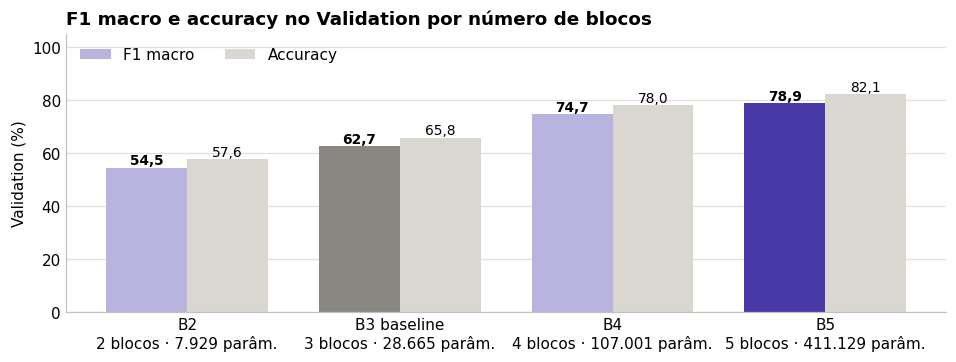

In [10]:
names = list(results)
f1 = np.array([results[n]["val"]["f1_macro"] for n in names]) * 100
acc = np.array([results[n]["val"]["accuracy"] for n in names]) * 100
best = names[int(f1.argmax())]

fig, ax = plt.subplots(figsize=(8.8, 3.4))
x = np.arange(len(names))
ax.bar(x - 0.19, f1, width=0.38, color=[C_SEL if n == best else C_BASE if n == "B3_baseline" else C_OTHER for n in names],
       label="F1 macro")
ax.bar(x + 0.19, acc, width=0.38, color="#d9d7cf", label="Accuracy")
for i in range(len(names)):
    ax.text(i - 0.19, f1[i] + 1.2, f"{f1[i]:.1f}".replace(".", ","), ha="center", fontsize=9, fontweight="bold")
    ax.text(i + 0.19, acc[i] + 1.2, f"{acc[i]:.1f}".replace(".", ","), ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([f"{n.replace('_', ' ')}\n{results[n]['n_blocks']} blocos · {br(results[n]['params'])} parâm." for n in names])
ax.set_ylim(0, 105); ax.set_ylabel("Validation (%)")
ax.set_title("F1 macro e accuracy no Validation por número de blocos")
ax.yaxis.grid(True, color="#e1e0d9", lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.legend(frameon=False, loc="upper left", ncols=2)
fig.tight_layout(); fig.savefig(FIG / "comparacao.png", dpi=200); plt.show()

### Curvas de treino e validação

Azul = Train, laranja = Validation; a linha pontilhada marca a melhor época no Validation (os pesos guardados).
- Se as duas curvas ficam juntas e ruins, o modelo não tem capacidade suficiente: **underfitting**.
- Se a de Train continua melhorando e a de Validation para ou piora, o modelo está decorando o Train: **overfitting**.

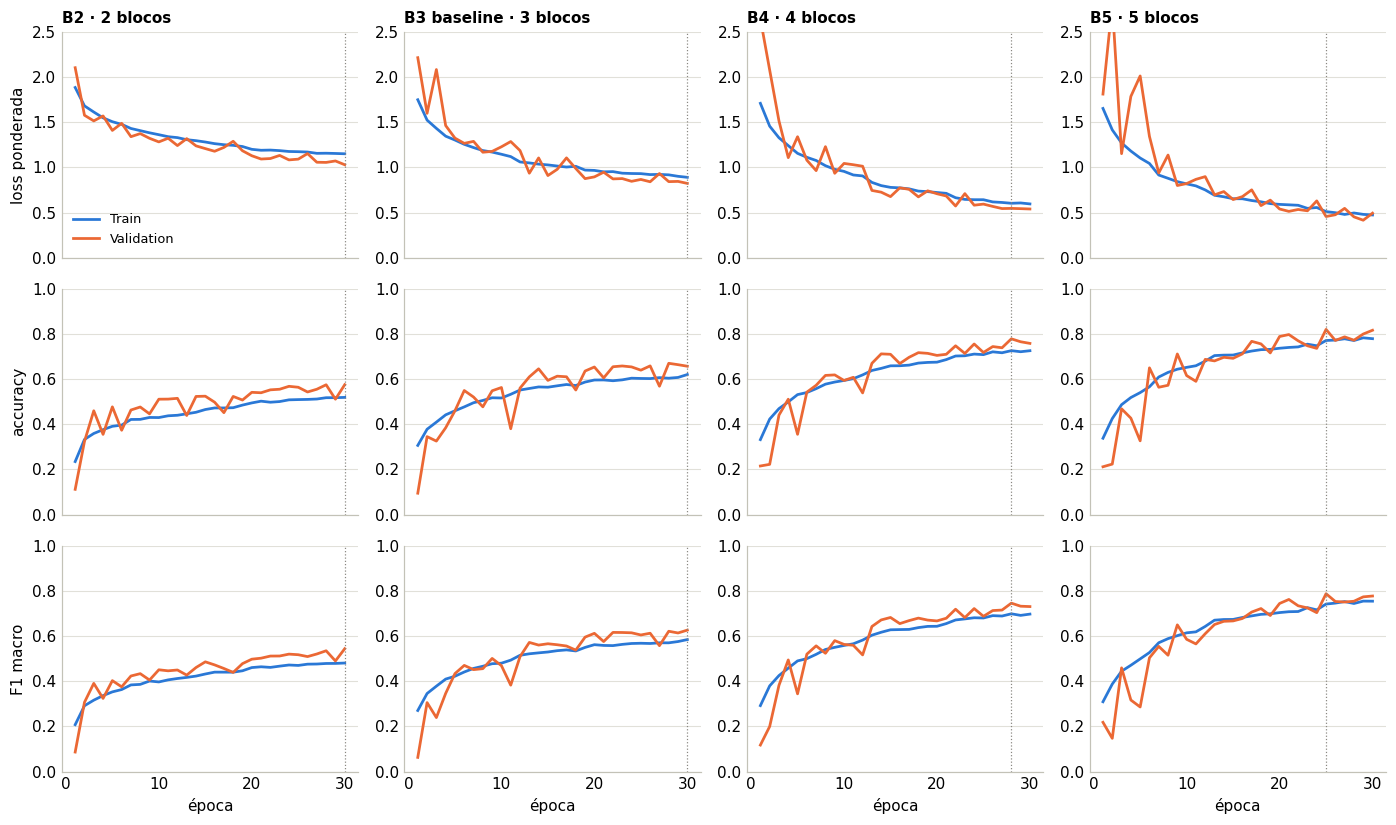

In [11]:
fig, axes = plt.subplots(3, len(names), figsize=(3.2 * len(names), 7.6), sharex="col")
for j, n in enumerate(names):
    h = results[n]["history"]
    ep = np.arange(1, len(h["loss"]) + 1)
    for i, (k, vk, lab) in enumerate((("loss", "val_loss", "loss ponderada"), ("accuracy", "val_accuracy", "accuracy"),
                                      ("f1", "val_f1", "F1 macro"))):
        ax = axes[i, j]
        ax.plot(ep, h[k], color=C_TRAIN, lw=1.8, label="Train")
        ax.plot(ep, h[vk], color=C_VAL, lw=1.8, label="Validation")
        ax.axvline(results[n]["best_epoch"], color="#898781", lw=0.8, ls=":")
        ax.yaxis.grid(True, color="#e1e0d9", lw=0.7); ax.set_axisbelow(True); ax.tick_params(length=0)
        if i:
            ax.set_ylim(0, 1)
        if j == 0:
            ax.set_ylabel(lab)
    axes[0, j].set_title(f"{n.replace('_', ' ')} · {results[n]['n_blocks']} blocos", fontsize=10)
    axes[2, j].set_xlabel("época")
axes[0, 0].legend(frameon=False, fontsize=8.5)
top = max(max(r["history"]["loss"][1:] + r["history"]["val_loss"][1:] or [2.2]) for r in results.values())
for ax in axes[0]:
    ax.set_ylim(0, min(top * 1.05, 2.5))
fig.tight_layout(); fig.savefig(FIG / "curvas.png", dpi=200); plt.show()

In [12]:
def line(n):
    r, v = results[n], results[n]["val"]
    d = "" if n == "B3_baseline" else f", {pp(v['f1_macro'] - base['f1_macro'])} vs. baseline"
    return (f"- **{n.replace('_', ' ')}** ({r['n_blocks']} blocos, {br(r['params'])} parâmetros, campo receptivo {r['receptive_field']} px): "
            f"F1 macro **{pc(v['f1_macro'])}**{d}; melhor época {r['best_epoch']} de {r['epochs_run']}; {diagnose(r['history'], r['best_epoch'])}.")


steps = [(a, b, results[b]["val"]["f1_macro"] - results[a]["val"]["f1_macro"]) for a, b in zip(names, names[1:])]
big = max(steps, key=lambda s: abs(s[2]))
display(Markdown("### Leitura dos resultados\n\n" + "\n".join(line(n) for n in names) + f"""

**Passo de profundidade com maior efeito:** de {results[big[0]]['n_blocks']} para {results[big[1]]['n_blocks']} blocos ({pp(big[2])} de F1 macro).
Passos: """ + " · ".join(f"{results[a]['n_blocks']}→{results[b]['n_blocks']}: {pp(d)}" for a, b, d in steps)))

### Leitura dos resultados

- **B2** (2 blocos, 7.929 parâmetros, campo receptivo 10 px): F1 macro **54,5%**, −8,2 p.p. vs. baseline; melhor época 30 de 30; underfitting.
- **B3 baseline** (3 blocos, 28.665 parâmetros, campo receptivo 22 px): F1 macro **62,7%**; melhor época 30 de 30; underfitting.
- **B4** (4 blocos, 107.001 parâmetros, campo receptivo 46 px): F1 macro **74,7%**, +12,0 p.p. vs. baseline; melhor época 28 de 30; underfitting.
- **B5** (5 blocos, 411.129 parâmetros, campo receptivo 94 px): F1 macro **78,9%**, +16,1 p.p. vs. baseline; melhor época 25 de 30; underfitting.

**Passo de profundidade com maior efeito:** de 3 para 4 blocos (+12,0 p.p. de F1 macro).
Passos: 2→3: +8,2 p.p. · 3→4: +12,0 p.p. · 4→5: +4,2 p.p.

## 6. Arquitetura selecionada

**Regra, definida antes de olhar o Test:** fica o modelo de **maior F1 macro no Validation**. Se outro ficar a menos de 1 p.p. dele, a diferença está dentro do ruído de um Validation com ~2.600 imagens e uma única seed; nesse caso fica o de **menos parâmetros**. A melhor arquitetura não é necessariamente a maior.

In [13]:
SELECTED, tied = select(results, margin=MARGIN)
sel = results[SELECTED]
sv = sel["val"]
(OUT / "selection.json").write_text(json.dumps({"name": SELECTED, "tied": tied, "margin": MARGIN}, indent=1))
others = [n for n in tied if n != SELECTED]
display(Markdown(f"""
### Selecionado: **{SELECTED.replace('_', ' ')}** ({sel['n_blocks']} blocos, filtros {'-'.join(map(str, sel['filters']))})

- **Validation:** F1 macro **{pc(sv['f1_macro'])}**, accuracy {pc(sv['accuracy'])}, precision {pc(sv['precision_macro'])}, recall {pc(sv['recall_macro'])}.
- **Em relação à baseline:** {pp(sv['f1_macro'] - base['f1_macro'])} de F1 macro, com {br(sel['params'])} parâmetros (baseline: {br(results['B3_baseline']['params'])}).
- **Empate dentro de {pp(MARGIN)}:** {('com ' + ', '.join(others) + ' → fica o de menos parâmetros') if others else 'nenhum outro modelo'}.
- **Curvas:** {diagnose(sel['history'], sel['best_epoch'])}; melhor época {sel['best_epoch']} de {sel['epochs_run']}.
"""))
display(pd.DataFrame({"Precision": sv["precision"], "Recall": sv["recall"], "F1": sv["f1"]}, index=CLASSES)
        .map(pc).rename_axis("Validation, por classe"))


### Selecionado: **B5** (5 blocos, filtros 16-32-64-128-256)

- **Validation:** F1 macro **78,9%**, accuracy 82,1%, precision 74,6%, recall 85,2%.
- **Em relação à baseline:** +16,1 p.p. de F1 macro, com 411.129 parâmetros (baseline: 28.665).
- **Empate dentro de +1,0 p.p.:** nenhum outro modelo.
- **Curvas:** underfitting; melhor época 25 de 30.


,Precision,Recall,F1
"Validation, por classe",,,
Chinee apple,"66,7%","70,2%","68,4%"
Lantana,"69,2%","91,8%","78,9%"
Parkinsonia,"68,2%","96,1%","79,8%"
Parthenium,"70,3%","89,0%","78,5%"
Prickly acacia,"78,2%","85,5%","81,7%"
Rubber vine,"75,0%","90,8%","82,1%"
Siam weed,"70,3%","96,9%","81,5%"
Snake weed,"77,0%","68,0%","72,2%"
Negative,"96,7%","78,6%","86,7%"


## 7. Avaliação final no Test

É a **primeira e única** vez que as imagens do Test são lidas. O resultado fica salvo em `test.json`. Se a célula for executada de novo, ela só mostra o que já foi salvo, sem reavaliar.

In [14]:
test_path = OUT / "test.json"
test_df = df[df.split == "test"].reset_index(drop=True)
if test_path.exists():
    test = json.loads(test_path.read_text())
    assert test["name"] == SELECTED, "o Test já foi usado com outro modelo; não reavaliar"
    print("Test já avaliado para", SELECTED, "-> mostrando o resultado salvo.")
else:
    test_ds, y_test = eval_images("test")
    model = build_cnn(sel["n_blocks"], name=SELECTED)
    model.load_weights(str(RUNS / SELECTED / "best.weights.h5"))
    prob = model.predict(test_ds, verbose=0)
    test = {"name": SELECTED, "n": int(len(y_test)), **metrics(y_test, prob.argmax(1), K)}
    test_path.write_text(json.dumps(test, indent=1))
    pd.DataFrame({"file": test_df.file, "true": y_test, "pred": prob.argmax(1), "conf": prob.max(1)}
                 ).to_csv(OUT / "test_predictions.csv", index=False)
pred = pd.read_csv(OUT / "test_predictions.csv")

display(Markdown(f"""
### Resultado final no Test: {SELECTED.replace('_', ' ')} ({br(test['n'])} imagens)

| Accuracy | Precision (macro) | Recall (macro) | **F1 macro** |
|---|---|---|---|
| {pc(test['accuracy'])} | {pc(test['precision_macro'])} | {pc(test['recall_macro'])} | **{pc(test['f1_macro'])}** |

No Validation o mesmo modelo teve F1 macro {pc(sv['f1_macro'])} e accuracy {pc(sv['accuracy'])} ({pp(test['f1_macro'] - sv['f1_macro'])} de F1 no Test).
"""))
display(pd.DataFrame({"Precision": test["precision"], "Recall": test["recall"], "F1": test["f1"]}, index=CLASSES)
        .map(pc).assign(Imagens=np.array(test["confusion"]).sum(axis=1)).rename_axis("Test, por classe"))


### Resultado final no Test: B5 (2.627 imagens)

| Accuracy | Precision (macro) | Recall (macro) | **F1 macro** |
|---|---|---|---|
| 80,5% | 72,8% | 83,8% | **77,1%** |

No Validation o mesmo modelo teve F1 macro 78,9% e accuracy 82,1% (−1,7 p.p. de F1 no Test).


,Precision,Recall,F1,Imagens
"Test, por classe",,,,
Chinee apple,"61,4%","66,9%","64,0%",169
Lantana,"65,0%","89,4%","75,3%",160
Parkinsonia,"67,4%","96,1%","79,3%",155
Parthenium,"69,5%","92,2%","79,2%",153
Prickly acacia,"86,5%","84,4%","85,4%",160
Rubber vine,"73,1%","90,1%","80,7%",151
Siam weed,"65,8%","91,9%","76,7%",161
Snake weed,"70,1%","66,4%","68,2%",152
Negative,"96,4%","76,8%","85,5%",1366


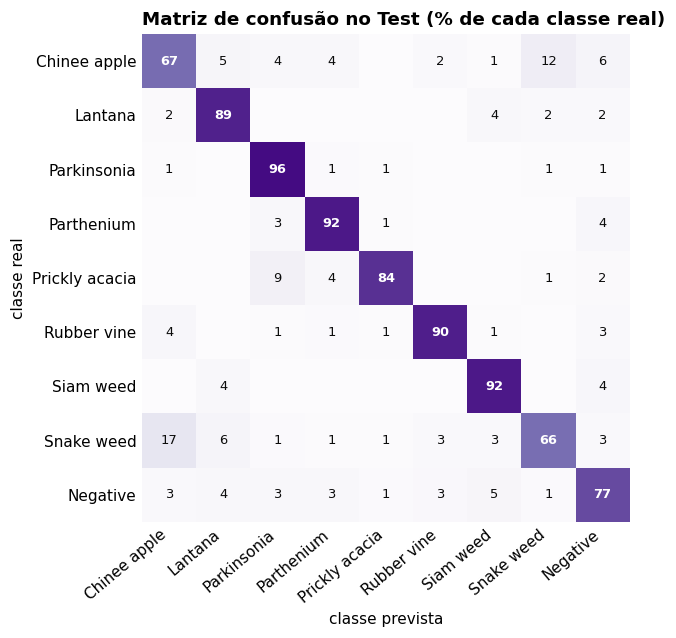

Maior confusão: 17% das imagens de 'Snake weed' foram previstas como 'Chinee apple'.


In [15]:
cm = np.array(test["confusion"])
pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(6.8, 5.9))
ax.imshow(pct, cmap="Purples", vmin=0, vmax=100)
for i in range(K):
    for j in range(K):
        if cm[i, j]:
            ax.text(j, i, f"{pct[i, j]:.0f}", ha="center", va="center", fontsize=8.5,
                    color="white" if pct[i, j] > 55 else "#0b0b0b", fontweight="bold" if i == j else "normal")
ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, rotation=40, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("classe prevista"); ax.set_ylabel("classe real")
ax.set_title("Matriz de confusão no Test (% de cada classe real)")
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
fig.tight_layout(); fig.savefig(FIG / "matriz_confusao_test.png", dpi=200); plt.show()

off = pct.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"Maior confusão: {off[i, j]:.0f}% das imagens de '{CLASSES[i]}' foram previstas como '{CLASSES[j]}'.")

### Exemplos de acertos e erros no Test

Linha de cima: acertos (contorno verde). Linha de baixo: erros (contorno vermelho), com a classe prevista, a confiança do modelo e a classe real. As imagens são sorteadas com seed fixa, sem escolher a dedo. Cada uma aparece com o mesmo crop central 224×224 que o modelo recebeu.

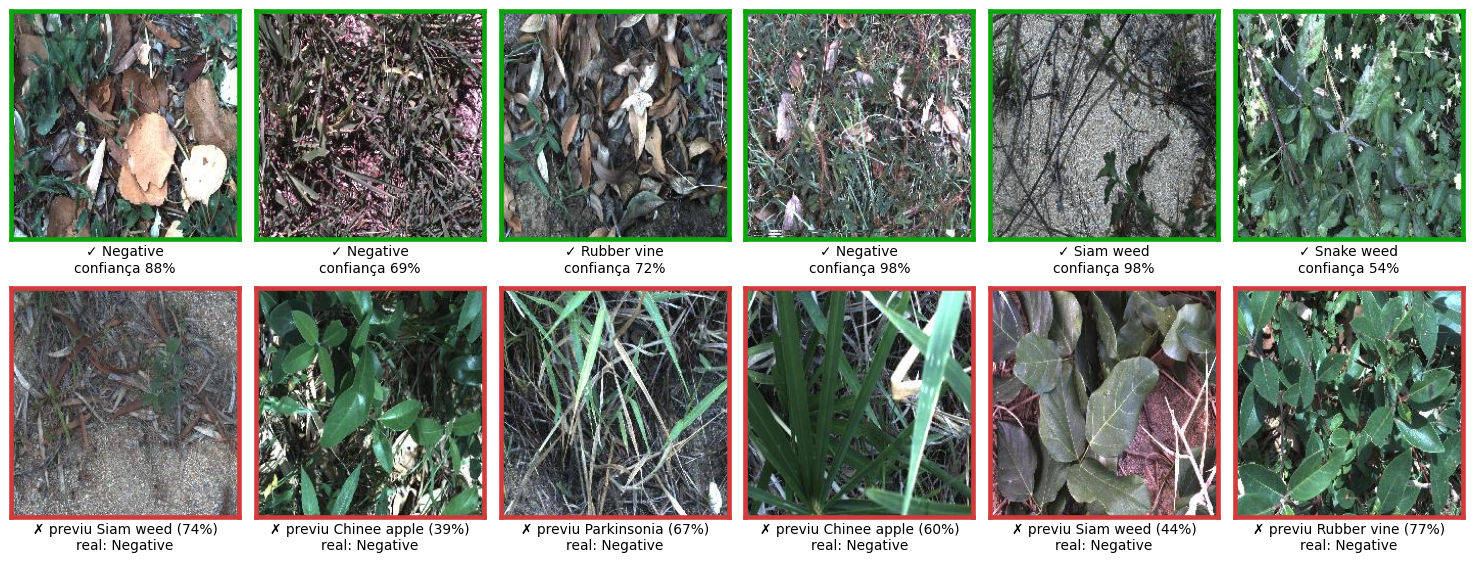

Acertos: 2.115 de 2.627 | erros: 512 | confiança média nos acertos 87,5%, nos erros 62,3%


In [16]:
rng = np.random.default_rng(SEED)
ok, err = pred.index[pred.true == pred.pred].to_numpy(), pred.index[pred.true != pred.pred].to_numpy()
o = (SIDE - SIZE) // 2
fig, axes = plt.subplots(2, 6, figsize=(13.5, 5.4))
for r_, (pool, col) in enumerate(((ok, "#0ca30c"), (err, "#d03b3b"))):
    picks = rng.choice(pool, min(6, len(pool)), replace=False) if len(pool) else []
    for ax in axes[r_]:
        ax.axis("off")
    for ax, k in zip(axes[r_], picks):
        row = pred.loc[k]
        ax.axis("on")
        ax.imshow(np.asarray(Image.open(test_df.path[k]).convert("RGB"))[o:o + SIZE, o:o + SIZE])
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(True); s.set_edgecolor(col); s.set_linewidth(3)
        if r_ == 0:
            ax.set_xlabel(f"✓ {CLASSES[int(row.pred)]}\nconfiança {row.conf * 100:.0f}%", fontsize=9)
        else:
            ax.set_xlabel(f"✗ previu {CLASSES[int(row.pred)]} ({row.conf * 100:.0f}%)\nreal: {CLASSES[int(row.true)]}", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "exemplos_test.png", dpi=130); plt.show()
print(f"Acertos: {br(len(ok))} de {br(len(pred))} | erros: {br(len(err))} | "
      f"confiança média nos acertos {pc(pred.conf[ok].mean())}, nos erros {pc(pred.conf[err].mean()) if len(err) else '—'}")

## 8. Conclusão

In [17]:
worst = int(np.argmin(test["recall"]))
display(Markdown(f"""
### Qual alteração arquitetural teve maior impacto?

A única alteração investigada foi a **profundidade** (número de blocos convolucionais), com todo o resto fixo. O passo de maior efeito foi de **{results[big[0]]['n_blocks']} para {results[big[1]]['n_blocks']} blocos: {pp(big[2])} de F1 macro no Validation**.

| Modelo | Blocos | Parâmetros | Campo receptivo | F1 macro (Val) | Leitura das curvas |
|---|---|---|---|---|---|
""" + "\n".join(f"| {n.replace('_', ' ')} | {r['n_blocks']} | {br(r['params'])} | {r['receptive_field']} px | {pc(r['val']['f1_macro'])} | {diagnose(r['history'], r['best_epoch'])} |"
                for n, r in results.items()) + f"""

### Modelo final

**{SELECTED.replace('_', ' ')}**: F1 macro de **{pc(sv['f1_macro'])} no Validation** e **{pc(test['f1_macro'])} no Test** (accuracy no Test: {pc(test['accuracy'])}).

### Limitações observadas

- **Uma seed por modelo:** diferenças menores que ~1 p.p. não são conclusivas; por isso a regra de empate na escolha.
- **Test otimista para locais novos:** como medido na Sprint 3, 99,8% das fotos de Validation/Test têm uma foto de Train da mesma sessão de captura e classe. O resultado vale para fotos parecidas com as do treino; em outro local, deve cair.
- **Classe mais difícil no Test:** {CLASSES[worst]} (recall de {pc(test['recall'][worst])}).
- **Uma pergunta só:** filtros, kernel, tipo de pooling, GAP × Flatten e tamanho da Dense ficaram fixos; o melhor valor deles pode mudar com a profundidade.
- **Redes pequenas treinadas do zero**, sem *transfer learning*, em até {EPOCHS} épocas.

### O que testaríamos na próxima etapa

1. Sobre o modelo escolhido: mais filtros (32 → 64 → …) e kernel 5×5, uma mudança por vez.
2. GAP × Flatten e Dense 64 × 256, para ver se a cabeça da rede limita o resultado.
3. Repetir os melhores com 3 seeds (média ± desvio) e avaliar num split por sessão de captura.
4. *Transfer learning* (MobileNet ou ResNet pré-treinadas) como referência de teto.
"""))


### Qual alteração arquitetural teve maior impacto?

A única alteração investigada foi a **profundidade** (número de blocos convolucionais), com todo o resto fixo. O passo de maior efeito foi de **3 para 4 blocos: +12,0 p.p. de F1 macro no Validation**.

| Modelo | Blocos | Parâmetros | Campo receptivo | F1 macro (Val) | Leitura das curvas |
|---|---|---|---|---|---|
| B2 | 2 | 7.929 | 10 px | 54,5% | underfitting |
| B3 baseline | 3 | 28.665 | 22 px | 62,7% | underfitting |
| B4 | 4 | 107.001 | 46 px | 74,7% | underfitting |
| B5 | 5 | 411.129 | 94 px | 78,9% | underfitting |

### Modelo final

**B5**: F1 macro de **78,9% no Validation** e **77,1% no Test** (accuracy no Test: 80,5%).

### Limitações observadas

- **Uma seed por modelo:** diferenças menores que ~1 p.p. não são conclusivas; por isso a regra de empate na escolha.
- **Test otimista para locais novos:** como medido na Sprint 3, 99,8% das fotos de Validation/Test têm uma foto de Train da mesma sessão de captura e classe. O resultado vale para fotos parecidas com as do treino; em outro local, deve cair.
- **Classe mais difícil no Test:** Snake weed (recall de 66,4%).
- **Uma pergunta só:** filtros, kernel, tipo de pooling, GAP × Flatten e tamanho da Dense ficaram fixos; o melhor valor deles pode mudar com a profundidade.
- **Redes pequenas treinadas do zero**, sem *transfer learning*, em até 30 épocas.

### O que testaríamos na próxima etapa

1. Sobre o modelo escolhido: mais filtros (32 → 64 → …) e kernel 5×5, uma mudança por vez.
2. GAP × Flatten e Dense 64 × 256, para ver se a cabeça da rede limita o resultado.
3. Repetir os melhores com 3 seeds (média ± desvio) e avaliar num split por sessão de captura.
4. *Transfer learning* (MobileNet ou ResNet pré-treinadas) como referência de teto.


### Pacote de resultados

Gera `sprint4_resultados.zip` com as tabelas, os históricos (`runs/*/results.json` e `history.csv`), as figuras e as métricas do Test. Os pesos dos modelos ficam fora do zip; eles continuam salvos em `runs/`, no Drive. No Colab, o download começa sozinho.

In [18]:
pack = Path("sprint4_pacote")
shutil.rmtree(pack, ignore_errors=True)
shutil.copytree(OUT, pack, ignore=shutil.ignore_patterns("*.h5", "*.keras"))
zip_file = shutil.make_archive("sprint4_resultados", "zip", pack)
shutil.rmtree(pack)
print("Arquivo gerado:", zip_file, f"({Path(zip_file).stat().st_size / 2**20:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(zip_file)

Arquivo gerado: /content/sprint4_resultados.zip (2.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
**Reprodutibilidade:** seed 42 em todos os modelos. A divisão Train/Validation/Test é a do `splits.csv` da Sprint 3, embutida e conferida acima, e não é refeita. Operações da GPU podem causar pequenas variações entre execuções.
**Fonte dos dados:** Olsen, A. et al. *DeepWeeds: A Multiclass Weed Species Image Dataset for Deep Learning.* Scientific Reports 9, 2058 (2019), CC BY 4.0. https://github.com/AlexOlsen/DeepWeeds